# Лабораторная 2. Классическая обработка изображений

Задание целиком: `labs/lab02/README.md` в репозитории курса.

Ноутбук один на обе части:
- **Часть 1** (после лекции 2): освещённость и шум по всем фото, гистограммы, коррекция яркости, сравнение фильтров;
- **Часть 2** (после лекции 3): выделение животного на фото, проверка маски по разметке, признаки формы.

Как работать:
1. В первой ячейке впишите свой номер варианта.
2. Заполняйте ячейки с пометкой `TODO` сверху вниз. Ячейки без `TODO` уже готовы, их менять не нужно.
3. Пока вы не дошли до части 2, её ячейки можно не трогать: Run All проходит через них без ошибок.
4. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

В Kaggle включите интернет: Settings → Internet → On.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [1]:
VARIANT = 15   # TODO: ваш порядковый номер в списке группы, например 7
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab02/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: colab | папка данных: /content/data
Вариант 15: Bombay, Sphynx, american_bulldog, boxer
  Скачиваю https://github.com/ykvnkm/computer-vision-course/releases/download/data-v1/variant_15.zip
  variant_15.zip: 77.3 МБ, готово.                              
  Распаковываю в /content/data/variant_15 ...
Готово: /content/data/variant_15 (800 изображений)
данные варианта: /content/data/variant_15
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
import time

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from skimage.restoration import estimate_sigma
from skimage.metrics import structural_similarity

IMG_DIR = DATA_DIR / "images"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

labels = pd.read_csv(DATA_DIR / "labels.csv")
print(len(labels), "фото,", labels["breed"].nunique(), "породы:", ", ".join(labels["breed"].unique()))
print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

800 фото, 4 породы: american_bulldog, Bombay, boxer, Sphynx
OpenCV 5.0.0 | numpy 2.4.6 | pandas 2.2.3


### Общие функции

Готовый код, менять не нужно.

- `load_rgb(filename)` читает фото через Pillow с `.convert("RGB")` (в датасете есть файлы в режимах `L`, `RGBA`, `P`, это вы видели в лабе 1) и уменьшает его так, чтобы длинная сторона стала 512 px. Одинаковый масштаб нужен, чтобы ядро 5×5 действовало на всех фото одинаково.
- `load_trimap(filename, shape)` читает trimap и приводит его к размеру фото через `cv2.INTER_NEAREST`: значения 1, 2, 3 не смешиваются.
- `show_grid(images, titles, ncols, path)` рисует картинки сеткой и, если указан `path`, сохраняет PNG.

In [3]:
MAX_SIDE = 512   # длинная сторона после уменьшения, px


def load_rgb(filename):
    """Фото как RGB uint8, длинная сторона MAX_SIDE."""
    with Image.open(IMG_DIR / filename) as im:
        rgb = np.asarray(im.convert("RGB"))
    h, w = rgb.shape[:2]
    scale = MAX_SIDE / max(h, w)
    size = (round(w * scale), round(h * scale))           # cv2.resize ждёт (ширина, высота)
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    return cv2.resize(rgb, size, interpolation=interp)


def load_trimap(filename, shape):
    """Trimap того же размера, что фото: 1 = животное, 2 = фон, 3 = граница."""
    with Image.open(TRIMAP_DIR / (Path(filename).stem + ".png")) as im:
        tri = np.asarray(im)
    return cv2.resize(tri, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)


def show_grid(images, titles=None, ncols=4, path=None, size=3.0):
    """Картинки сеткой: RGB как есть, 2D-массивы в оттенках серого. path: куда сохранить PNG."""
    nrows = (len(images) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        ax = axes.ravel()[i]
        img = np.asarray(img)
        if img.dtype == bool:
            img = img.astype(np.uint8)
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=1 if img.max() <= 1 else 255)
        else:
            ax.imshow(img)
        if titles is not None:
            ax.set_title(titles[i], fontsize=9)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=100)
    plt.show()


example = load_rgb(labels["filename"].iloc[0])
print(labels["filename"].iloc[0], example.shape, example.dtype)

american_bulldog_2.jpg (341, 512, 3) uint8


# Часть 1. Освещённость, шум, фильтры

Делается после лекции 2. Результат части: четыре числа по каждому фото, гистограммы, сравнение способов поправить тёмные фото и сравнение фильтров на зашумлённых фото. Из этой части дальше понадобится одна переменная `BEST_FILTER`.

## 1.1 Четыре числа по каждому фото

| Число | Что показывает | Как считать |
|---|---|---|
| `mean_L` | средняя яркость | среднее канала L из `cv2.COLOR_RGB2LAB` (в 8-битном OpenCV L идёт от 0 до 255) |
| `std_L` | контраст | стандартное отклонение того же канала |
| `noise_sigma` | оценка шума в единицах яркости | `estimate_sigma(gray)` из `skimage.restoration` |
| `sharpness` | резкость: у размытого кадра мало перепадов | дисперсия `cv2.Laplacian(gray, cv2.CV_64F)` |

Допишите функцию `image_stats`. Следующая ячейка готова: она пройдёт по всем фото и сохранит `results/part1_stats.csv`.

In [4]:
def image_stats(rgb):
    """Словарь {"mean_L", "std_L", "noise_sigma", "sharpness"} для одного кадра."""
    # TODO: L = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0]
    L = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0]

    # TODO: gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    # TODO: верните четыре числа как float, например "mean_L": float(L.mean())
    mean_L = float(L.mean())
    std_L = float(L.std())
    noise_sigma = float(estimate_sigma(gray, channel_axis=None))
    sharpness = float(cv2.Laplacian(gray, cv2.CV_64F).var())

    return {
        "mean_L": mean_L,
        "std_L": std_L,
        "noise_sigma": noise_sigma,
        "sharpness": sharpness
    }

In [5]:
rows = []
for r in labels.itertuples():
    with Image.open(IMG_DIR / r.filename) as im:
        width, height = im.size                      # исходный размер файла
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "width": width, "height": height, **image_stats(load_rgb(r.filename))})
stats = pd.DataFrame(rows)
stats.to_csv(RESULTS / "part1_stats.csv", index=False, float_format="%.4f")
stats.describe().round(2)

,width,height,mean_L,std_L,noise_sigma,sharpness
count,800.00,800.00,800.00,800.00,800.00,800.00
mean,437.45,395.29,114.92,61.90,1.23,511.21
std,125.63,120.85,32.92,15.18,1.08,658.56
min,114.00,103.00,18.41,22.04,0.00,7.35
25%,334.00,333.00,94.01,52.29,0.53,128.68
50%,500.00,375.00,113.65,61.60,0.93,280.67
75%,500.00,500.00,134.42,70.86,1.53,590.86
max,1725.00,1600.00,213.70,109.14,7.88,4437.79


In [6]:
# TODO: средние четырёх чисел по породам: stats.groupby("breed")[[...]].mean().round(2)
#       Какая порода темнее остальных? У какой ниже резкость?
# Средние четырёх чисел по породам
breed_stats = stats.groupby("breed")[["mean_L", "std_L", "noise_sigma", "sharpness"]].mean().round(2)

display(breed_stats)

# Какая порода темнее остальных
print("Самая тёмная порода:", breed_stats["mean_L"].idxmin())

# У какой породы ниже резкость
print("Самая низкая резкость:", breed_stats["sharpness"].idxmin())

,mean_L,std_L,noise_sigma,sharpness
breed,,,,
Bombay,106.83,69.55,0.64,222.74
Sphynx,115.12,58.83,0.85,300.60
american_bulldog,115.60,60.40,1.56,698.98
boxer,122.15,58.81,1.87,822.50


Самая тёмная порода: Bombay
Самая низкая резкость: Bombay


## 1.2 Гистограммы

Нужен один рисунок `results/histograms.png`: распределение `mean_L` по всем фото и гистограммы каналов R, G, B самого тёмного и самого светлого фото. Рядом с гистограммами удобно показать сами фото.

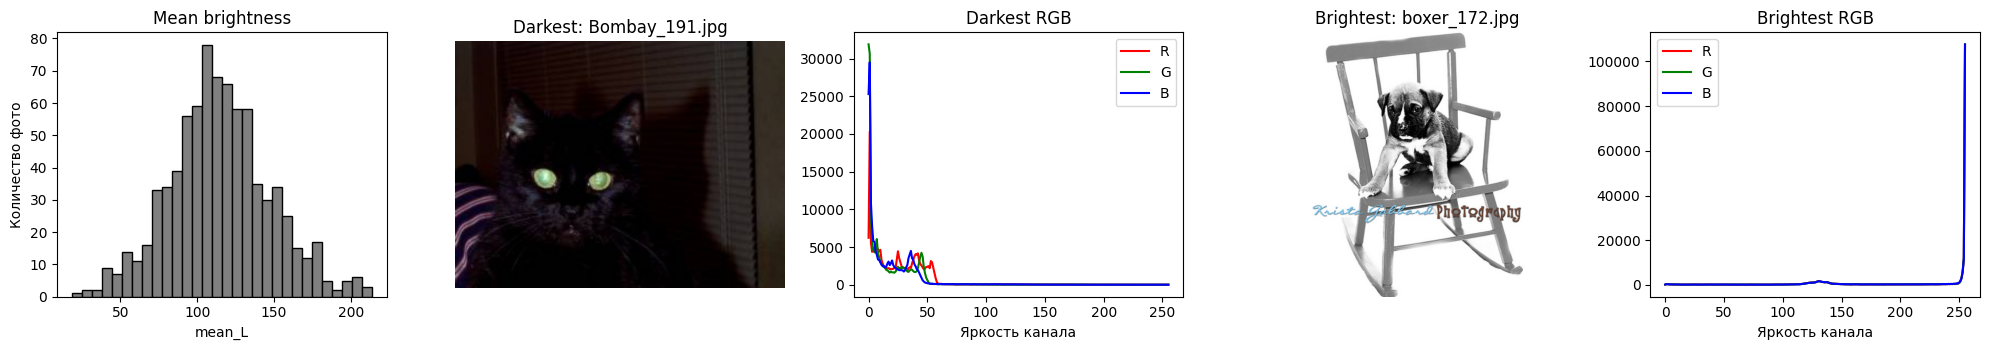

Самое тёмное фото: Bombay_191.jpg
Самое светлое фото: boxer_172.jpg
Сохранено: results/histograms.png


In [7]:
# TODO: самое тёмное и самое светлое фото: stats.loc[stats["mean_L"].idxmin(), "filename"] и idxmax()
# TODO: plt.subplots(1, 5, figsize=(20, 3.6)):
#       гистограмма stats["mean_L"] (bins=30), затем для каждого из двух фото само фото и гистограммы каналов.
#       Гистограмма канала c: np.bincount(rgb[..., c].ravel(), minlength=256) или cv2.calcHist
# TODO: plt.savefig(RESULTS / "histograms.png", dpi=100)


# Самое тёмное и самое светлое фото
darkest_file = stats.loc[stats["mean_L"].idxmin(), "filename"]
brightest_file = stats.loc[stats["mean_L"].idxmax(), "filename"]

# Загружаем фотографии
darkest_rgb = load_rgb(darkest_file)
brightest_rgb = load_rgb(brightest_file)

# Создаём рисунок из пяти частей
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))

# Распределение средней яркости всех фотографий
axes[0].hist(stats["mean_L"], bins=30, color="gray", edgecolor="black")
axes[0].set_title("Mean brightness")
axes[0].set_xlabel("mean_L")
axes[0].set_ylabel("Количество фото")

# Самая тёмная фотография
axes[1].imshow(darkest_rgb)
axes[1].set_title(f"Darkest: {darkest_file}")
axes[1].axis("off")

# Самая светлая фотография
axes[3].imshow(brightest_rgb)
axes[3].set_title(f"Brightest: {brightest_file}")
axes[3].axis("off")

# Гистограммы RGB для двух фотографий
for c, color, channel in zip(range(3), ["red", "green", "blue"], ["R", "G", "B"]):
    axes[2].plot(
        np.bincount(darkest_rgb[..., c].ravel(), minlength=256),
        color=color,
        label=channel
    )
    axes[4].plot(
        np.bincount(brightest_rgb[..., c].ravel(), minlength=256),
        color=color,
        label=channel
    )

axes[2].set_title("Darkest RGB")
axes[2].set_xlabel("Яркость канала")
axes[2].legend()

axes[4].set_title("Brightest RGB")
axes[4].set_xlabel("Яркость канала")
axes[4].legend()

plt.tight_layout()
plt.savefig(RESULTS / "histograms.png", dpi=100)
plt.show()

print("Самое тёмное фото:", darkest_file)
print("Самое светлое фото:", brightest_file)
print("Сохранено:", RESULTS / "histograms.png")


## 1.3 Освещённость

Возьмите 5 самых тёмных фото и сравните четыре способа их поправить:

| Метод | Что делает |
|---|---|
| `eq_rgb` | `cv2.equalizeHist` по каждому каналу R, G, B отдельно |
| `eq_L` | `cv2.equalizeHist` только по каналу L в Lab, каналы a и b не трогаем |
| `clahe_L` | CLAHE по каналу L: `cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))` |
| `gamma` | гамма-коррекция `255 * (x / 255) ** γ`; при γ < 1 тёмные места светлеют сильнее светлых |

Для каждого фото и метода нужны `mean_L` и `std_L` после коррекции и сдвиг цвета: насколько изменились каналы a и b в Lab. Функция `color_shift` готова.

In [8]:
def color_shift(before, after):
    """Средний сдвиг цвета |Δa| + |Δb| в Lab между двумя RGB-кадрами. 0 = оттенки не изменились."""
    lab0 = cv2.cvtColor(before, cv2.COLOR_RGB2LAB).astype(np.float32)
    lab1 = cv2.cvtColor(after, cv2.COLOR_RGB2LAB).astype(np.float32)
    return float(np.abs(lab1[..., 1:] - lab0[..., 1:]).sum(axis=2).mean())

In [9]:
GAMMA = 0.5   # можно подобрать своё значение


def correct(rgb, method):
    """method: "eq_rgb", "eq_L", "clahe_L" или "gamma". Возвращает RGB uint8 того же размера."""

    if method == "eq_rgb":
        # Выравниваем гистограмму каждого RGB-канала отдельно
        channels = cv2.split(rgb)
        equalized = [cv2.equalizeHist(channel) for channel in channels]
        return cv2.merge(equalized)

    elif method == "eq_L" or method == "clahe_L":
        # Переводим изображение в LAB
        L, a, b = cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))

        if method == "eq_L":
            L = cv2.equalizeHist(L)

        elif method == "clahe_L":
            clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
            L = clahe.apply(L)

        # Собираем LAB и возвращаем RGB
        lab = cv2.merge([L, a, b])
        return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    elif method == "gamma":
        # Создаём таблицу преобразования яркости
        lut = np.array([
            255 * (i / 255) ** GAMMA for i in range(256)
        ]).astype(np.uint8)

        return cv2.LUT(rgb, lut)

    else:
        raise ValueError(f"Неизвестный метод коррекции: {method}")


,mean_L,std_L,color_shift
method,,,
clahe_L,45.69,50.73,0.40
eq_L,118.07,75.44,0.33
eq_rgb,119.20,77.55,13.21
gamma,71.25,52.64,6.21
original,28.80,40.62,0.00


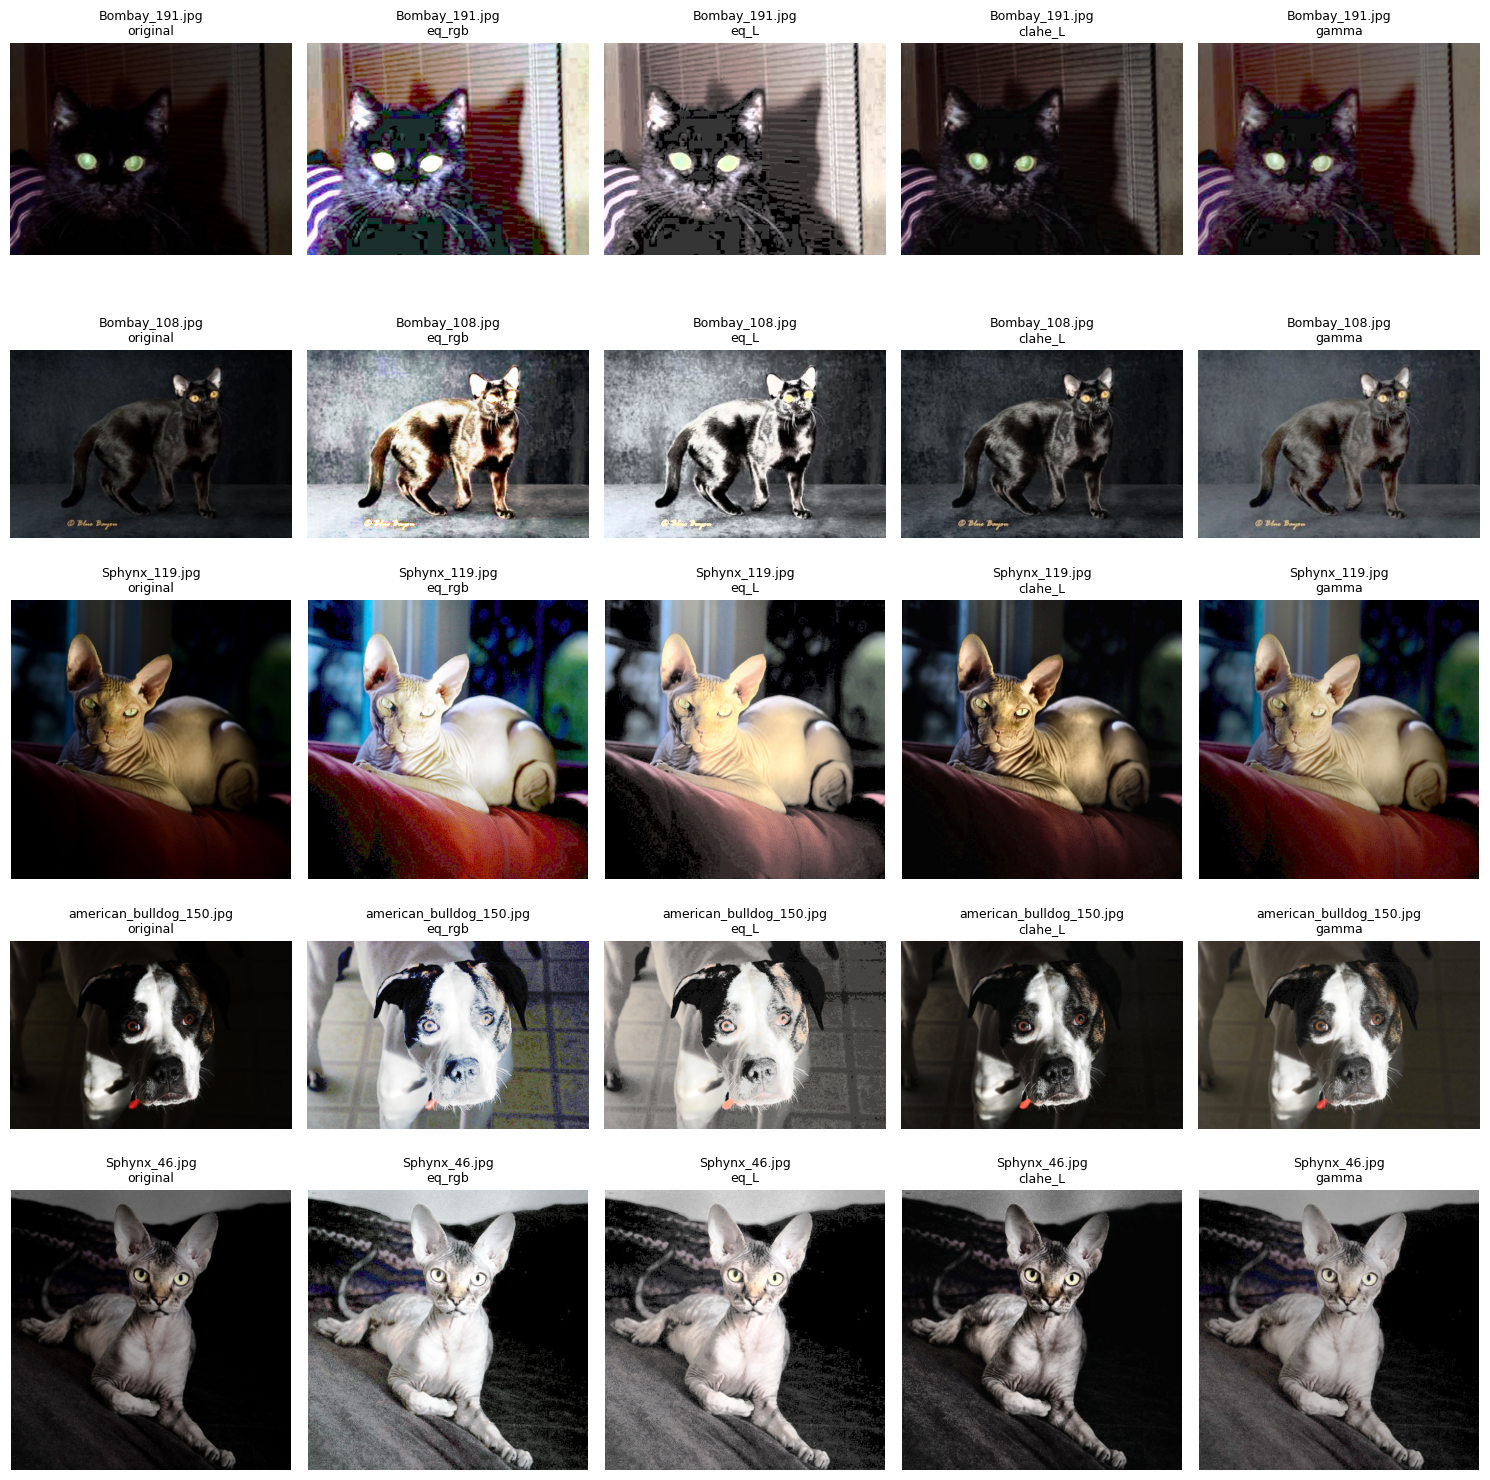

In [10]:

METHODS = ["eq_rgb", "eq_L", "clahe_L", "gamma"]

# Выбираем 5 самых тёмных фотографий
darkest = stats.nsmallest(5, "mean_L")

# Список для хранения численных результатов
illum_rows = []

# Списки изображений и подписей для сетки
illum_images = []
illum_titles = []

for r in darkest.itertuples():
    # Загружаем исходное изображение
    rgb = load_rgb(r.filename)

    # Добавляем оригинал
    illum_images.append(rgb)
    illum_titles.append(f"{r.filename}\noriginal")

    # Исходные показатели
    original_lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    original_L = original_lab[..., 0]

    illum_rows.append({
        "filename": r.filename,
        "method": "original",
        "mean_L": float(original_L.mean()),
        "std_L": float(original_L.std()),
        "color_shift": 0.0
    })

    # Применяем каждый метод коррекции
    for method in METHODS:
        corrected = correct(rgb, method)

        lab = cv2.cvtColor(corrected, cv2.COLOR_RGB2LAB)
        L = lab[..., 0]

        illum_rows.append({
            "filename": r.filename,
            "method": method,
            "mean_L": float(L.mean()),
            "std_L": float(L.std()),
            "color_shift": color_shift(rgb, corrected)
        })

        illum_images.append(corrected)
        illum_titles.append(f"{r.filename}\n{method}")

# Создаём таблицу результатов
illum = pd.DataFrame(illum_rows)

# Средние показатели по каждому методу
display(
    illum.groupby("method")[["mean_L", "std_L", "color_shift"]]
    .mean()
    .round(2)
)

# Выводим сетку 5 × 5
show_grid(
    illum_images,
    titles=illum_titles,
    ncols=5,
    path=RESULTS / "illumination.png"
)


## 1.4 Свёртка руками

`cv2.blur(img, (3, 3))` усредняет каждый пиксель с восемью соседями. То же самое делает свёртка `cv2.filter2D` с ядром 3×3, в котором все девять чисел равны 1/9. Проверьте это на любом фото.

Максимальная разница: 0
Средняя разница: 0.0


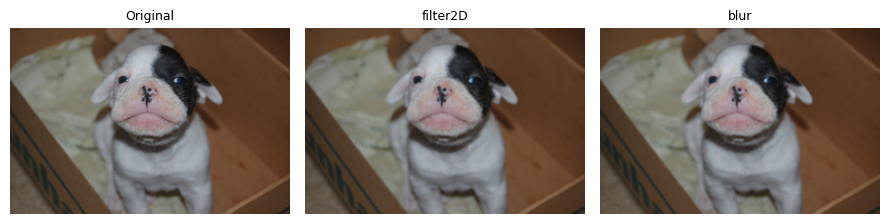

In [11]:

# Загружаем любое фото
img = load_rgb(labels["filename"].iloc[0])

# Создаём ядро усреднения 3×3
kernel = np.ones((3, 3), np.float32) / 9

# Применяем свёртку вручную через filter2D
filtered = cv2.filter2D(img, -1, kernel)

# Применяем готовое размытие blur
blurred = cv2.blur(img, (3, 3))

# Сравниваем результаты
diff = np.abs(filtered.astype(int) - blurred.astype(int))

print("Максимальная разница:", diff.max())
print("Средняя разница:", diff.mean())

# Показываем исходное изображение и оба результата
show_grid(
    [img, filtered, blurred],
    titles=["Original", "filter2D", "blur"],
    ncols=3
)


## 1.5 Шум и фильтры

У каждого варианта свой шум, он задан в `NOISE_PLAN`:

- `gauss`: к каждому пикселю добавлено случайное число из нормального распределения со стандартным отклонением `sigma` (в единицах яркости 0..255);
- `sp` («соль и перец»): доля `amount` пикселей стала чисто чёрной или чисто белой;
- `mix`: оба шума сразу.

Шум добавляется к 30 случайным фото варианта. Фильтр получает зашумлённое фото, результат сравнивается с исходным:

- PSNR в децибелах (`cv2.PSNR`): чем больше, тем ближе к исходному;
- SSIM от 0 до 1 (`structural_similarity`): похожесть по локальной структуре, ближе к тому, что видит глаз;
- время на кадр в миллисекундах.

Сравните `cv2.blur`, `cv2.GaussianBlur`, `cv2.medianBlur` с ядрами 3, 5, 7 и `cv2.bilateralFilter`. По желанию добавьте `cv2.fastNlMeansDenoisingColored`.

In [12]:
NOISE_PLAN = {
    0: {"kind": "gauss", "sigma": 20},
    1: {"kind": "sp", "amount": 0.05},
    2: {"kind": "mix", "sigma": 15, "amount": 0.03},
    3: {"kind": "gauss", "sigma": 30},
    4: {"kind": "sp", "amount": 0.10},
    5: {"kind": "mix", "sigma": 20, "amount": 0.05},
    6: {"kind": "gauss", "sigma": 10},
    7: {"kind": "sp", "amount": 0.02},
    8: {"kind": "mix", "sigma": 10, "amount": 0.02},
    9: {"kind": "gauss", "sigma": 25},
    10: {"kind": "sp", "amount": 0.08},
    11: {"kind": "mix", "sigma": 15, "amount": 0.05},
    12: {"kind": "gauss", "sigma": 15},
    13: {"kind": "sp", "amount": 0.04},
    14: {"kind": "mix", "sigma": 20, "amount": 0.03},
    15: {"kind": "gauss", "sigma": 30},
    16: {"kind": "sp", "amount": 0.06},
    17: {"kind": "mix", "sigma": 10, "amount": 0.04},
    18: {"kind": "gauss", "sigma": 20},
    19: {"kind": "sp", "amount": 0.03},
    20: {"kind": "mix", "sigma": 25, "amount": 0.05},
    21: {"kind": "gauss", "sigma": 25},
    22: {"kind": "sp", "amount": 0.10},
}


def add_noise(rgb, kind, sigma=0, amount=0.0, seed=0):
    """Зашумлённая копия RGB-кадра. kind: "gauss", "sp" или "mix"."""
    rng = np.random.default_rng(seed)
    out = rgb.astype(np.float32)
    if kind in ("gauss", "mix"):
        out = out + rng.normal(0, sigma, out.shape)
    out = np.clip(out, 0, 255).astype(np.uint8)
    if kind in ("sp", "mix"):
        r = rng.random(out.shape[:2])
        out[r < amount / 2] = 0
        out[r > 1 - amount / 2] = 255
    return out

шум варианта: kind=gauss sigma=30


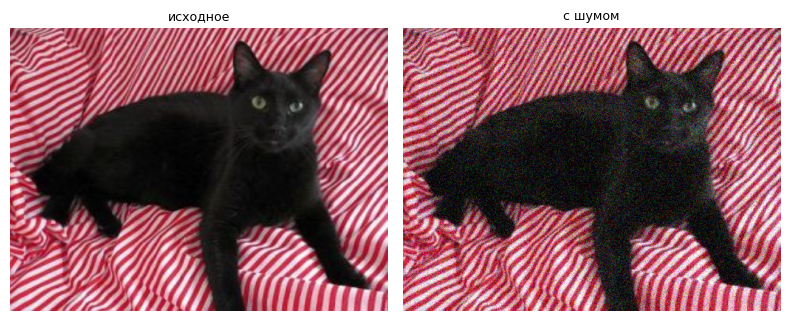

In [13]:
NOISE = NOISE_PLAN[VARIANT]
NOISE_NAME = " ".join(f"{k}={v}" for k, v in NOISE.items())
sample = labels.sample(30, random_state=VARIANT)
clean = [load_rgb(fn) for fn in sample["filename"]]
noisy = [add_noise(img, seed=VARIANT * 100 + i, **NOISE) for i, img in enumerate(clean)]
print("шум варианта:", NOISE_NAME)
show_grid([clean[0], noisy[0]], ["исходное", "с шумом"], ncols=2, size=4)

In [14]:
# TODO: словарь FILTERS: имя фильтра -> функция, которая принимает RGB uint8 и возвращает RGB uint8.
#       Нужны blur, GaussianBlur и medianBlur с ядрами 3, 5, 7 и bilateralFilter, например cv2.bilateralFilter(img, 9, 75, 75).
#       Пример записи: "median3": lambda img: cv2.medianBlur(img, 3)

FILTERS = {
    # Обычное усреднение
    "blur3": lambda img: cv2.blur(img, (3, 3)),
    "blur5": lambda img: cv2.blur(img, (5, 5)),
    "blur7": lambda img: cv2.blur(img, (7, 7)),

    # Гауссово размытие
    "gaussian3": lambda img: cv2.GaussianBlur(img, (3, 3), 0),
    "gaussian5": lambda img: cv2.GaussianBlur(img, (5, 5), 0),
    "gaussian7": lambda img: cv2.GaussianBlur(img, (7, 7), 0),

    # Медианный фильтр
    "median3": lambda img: cv2.medianBlur(img, 3),
    "median5": lambda img: cv2.medianBlur(img, 5),
    "median7": lambda img: cv2.medianBlur(img, 7),

    # Двусторонний фильтр
    "bilateral": lambda img: cv2.bilateralFilter(img, 9, 75, 75)
}


In [15]:

def quality(clean_img, out_img):
    """Насколько результат фильтра похож на чистый кадр: {"psnr": ..., "ssim": ...}."""

    # PSNR: чем больше значение, тем ближе результат к оригиналу
    psnr = float(cv2.PSNR(clean_img, out_img))

    # SSIM: структурное сходство от 0 до 1
    ssim = float(structural_similarity(
        clean_img,
        out_img,
        channel_axis=2,
        data_range=255
    ))

    return {
        "psnr": psnr,
        "ssim": ssim
    }


In [16]:
# Готовый цикл: каждый фильтр на 30 фото, время и качество. "none" = зашумлённое фото без фильтра.
rows = []
for name, f in {"none": lambda img: img, **FILTERS}.items():
    for fn, c, n in zip(sample["filename"], clean, noisy):
        t0 = time.perf_counter()
        out = f(n)
        ms = (time.perf_counter() - t0) * 1000
        rows.append({"filter": name, "filename": fn, "ms": ms, **quality(c, out)})
filt = pd.DataFrame(rows)
filt_summary = filt.groupby("filter").mean(numeric_only=True).round(4)
filt_summary.insert(0, "noise", NOISE_NAME)
filt_summary.to_csv(RESULTS / "filters.csv")
filt_summary

,noise,ms,psnr,ssim
filter,,,,
bilateral,kind=gauss sigma=30,28.5652,27.3226,0.6112
blur3,kind=gauss sigma=30,0.4931,27.1544,0.6001
blur5,kind=gauss sigma=30,0.4534,28.0351,0.7130
blur7,kind=gauss sigma=30,0.7176,27.3654,0.7271
gaussian3,kind=gauss sigma=30,1.0228,26.7166,0.5688
gaussian5,kind=gauss sigma=30,1.0032,28.0801,0.6710
gaussian7,kind=gauss sigma=30,1.0931,28.5139,0.7374
median3,kind=gauss sigma=30,0.3981,25.9072,0.5127
median5,kind=gauss sigma=30,1.7523,27.9717,0.6556


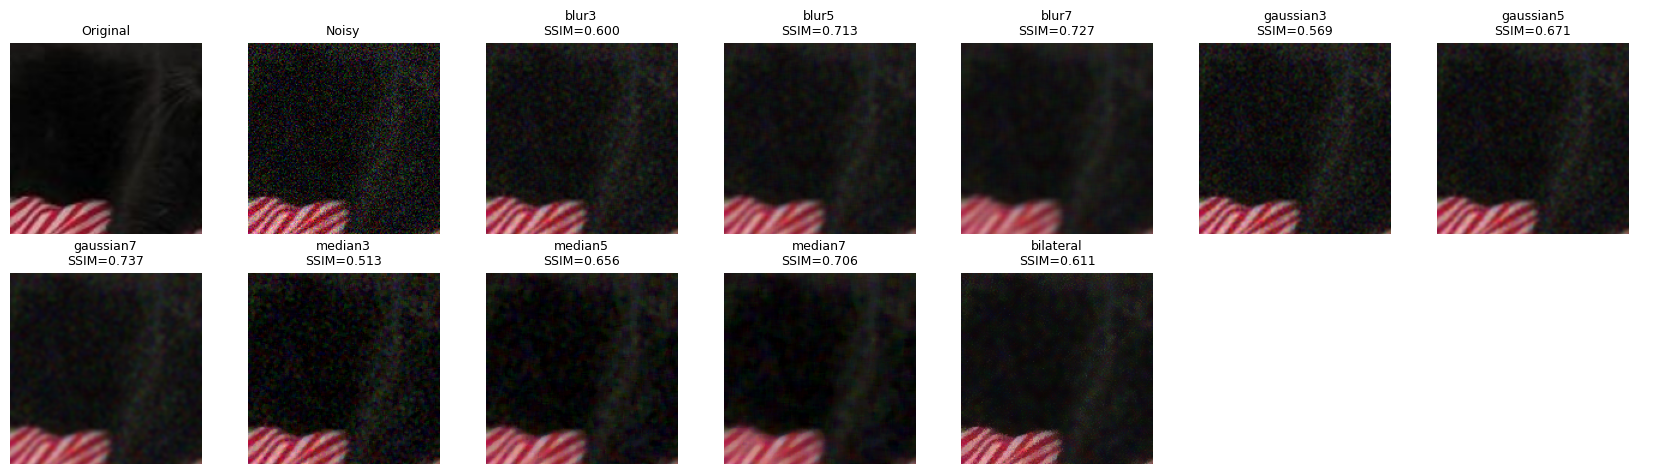

In [17]:
# TODO: кропы 160×160 из центра clean[0]: чистое, с шумом и после каждого фильтра из FILTERS.
#       В подписи удобно вписать SSIM фильтра из filt_summary.
#       show_grid(crops, titles, ncols=7, path=RESULTS / "filters.png", size=2.4)

# Кропы 160×160 из центра первой фотографии
def center_crop(img, size=160):
    h, w = img.shape[:2]
    y0 = (h - size) // 2
    x0 = (w - size) // 2
    return img[y0:y0 + size, x0:x0 + size]

crops = [
    center_crop(clean[0]),
    center_crop(noisy[0])
]

titles = ["Original", "Noisy"]

# Результаты каждого фильтра
for name, f in FILTERS.items():
    out = f(noisy[0])
    crops.append(center_crop(out))

    ssim_value = filt_summary.loc[name, "ssim"]
    titles.append(f"{name}\nSSIM={ssim_value:.3f}")

show_grid(
    crops,
    titles,
    ncols=7,
    path=RESULTS / "filters.png",
    size=2.4
)


In [18]:
# TODO: выберите лучший фильтр по таблице filt_summary (метрики, время) и по кропам.
#       Отсортировать таблицу: filt_summary.sort_values("ssim", ascending=False)
display(filt_summary.sort_values("ssim", ascending=False))
BEST_FILTER = "gaussian7"   # TODO: имя из FILTERS, например "median5"

,noise,ms,psnr,ssim
filter,,,,
gaussian7,kind=gauss sigma=30,1.0931,28.5139,0.7374
blur7,kind=gauss sigma=30,0.7176,27.3654,0.7271
blur5,kind=gauss sigma=30,0.4534,28.0351,0.7130
median7,kind=gauss sigma=30,35.7197,28.0976,0.7064
gaussian5,kind=gauss sigma=30,1.0032,28.0801,0.6710
median5,kind=gauss sigma=30,1.7523,27.9717,0.6556
bilateral,kind=gauss sigma=30,28.5652,27.3226,0.6112
blur3,kind=gauss sigma=30,0.4931,27.1544,0.6001
gaussian3,kind=gauss sigma=30,1.0228,26.7166,0.5688


По результатам сравнения фильтр **GaussianBlur с ядром 7×7 (gaussian7)** показал лучшие значения обеих метрик: PSNR = 28.5139 dB и SSIM = 0.7374, поэтому победители по двум метрикам совпали. Среднее время обработки составляет 1.0931 мс на изображение. На кропах заметно подавление шума при сохранении основных контуров объектов, однако мелкие детали шерсти частично сглаживаются, края становятся немного мягче, а остаточный шум полностью не исчезает.

# Часть 2 (после лекции 3). Выделение животного и признаки формы

Эту часть делайте после лекции 3. Кто хочет, может сделать её сразу: все функции и подсказки ниже.

Задача: получить маску животного без нейросети. Пайплайн: канал → порог Оцу → полярность → морфология → заливка дыр → самая большая связная компонента → контур и признаки формы. Качество маски проверяем по trimap через IoU, пиксели границы (значение 3) не учитываем.

Из части 1 сюда приходит только `BEST_FILTER`.

In [19]:
def iou_ignore(pred, trimap):
    """IoU маски pred с животным из trimap; пиксели границы (значение 3) не учитываются."""
    valid = trimap != 3
    gt = trimap == 1
    pred = np.asarray(pred) > 0
    inter = np.logical_and(pred, gt)[valid].sum()
    union = np.logical_or(pred, gt)[valid].sum()
    return float(inter / union) if union else float("nan")


def overlay(rgb, mask, color=(0, 255, 0), alpha=0.45):
    """Фото с маской, закрашенной полупрозрачным цветом."""
    out = rgb.copy()
    m = np.asarray(mask) > 0
    out[m] = ((1 - alpha) * out[m] + alpha * np.array(color)).astype(np.uint8)
    return out


# Каналы, из которых можно выбирать. Можно добавить свои.
CHANNELS = {
    "gray": lambda rgb: cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY),
    "S": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[1],
    "V": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[2],
    "L": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[0],
    "a": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[1],
    "b": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[2],
}

## 2.1 Один кадр по шагам

Пройдите пайплайн на одном фото и сохраните `results/pipeline.png`: исходное фото, trimap, серое, Оцу, после исправления полярности, после морфологии, после заливки и выбора компоненты, контур на фото, адаптивный порог для сравнения. В подписях укажите IoU масок.

Каждый шаг удобно сразу оформить функцией: в 2.2 из них соберётся `segment`.

In [20]:
EXAMPLE = labels["filename"].sample(1, random_state=VARIANT).iloc[0]   # можно заменить на любое фото варианта
rgb = load_rgb(EXAMPLE)
tri = load_trimap(EXAMPLE, rgb.shape)
print(EXAMPLE, rgb.shape, "значения trimap:", np.unique(tri))

Bombay_76.jpg (384, 512, 3) значения trimap: [1 2 3]


Порог Оцу: 103.0


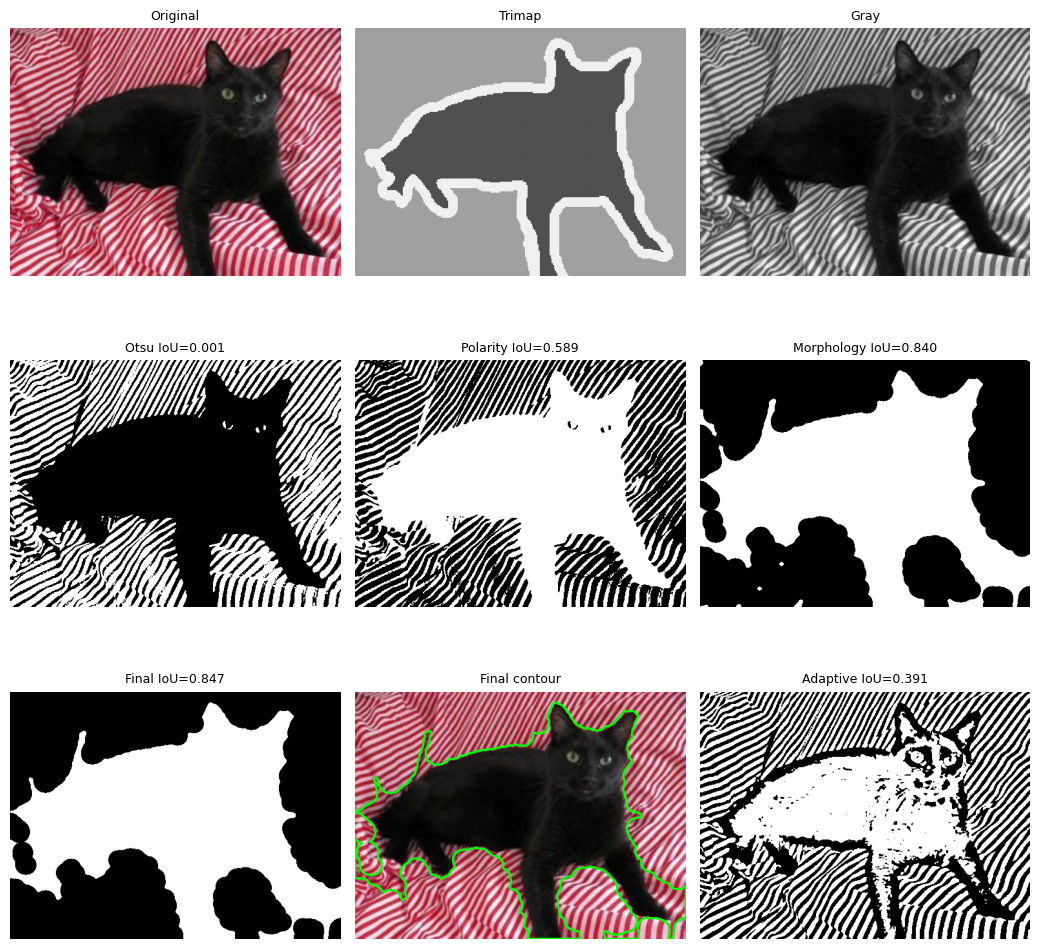

In [21]:
# TODO: gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
# TODO: Оцу: t, m = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU); напечатайте найденный порог t
# TODO: полярность: если в рамке шириной 10 px по краям кадра больше половины пикселей белые,
#       белым стал фон: инвертируйте маску (cv2.bitwise_not)
# TODO: морфология: cv2.morphologyEx с cv2.MORPH_OPEN, затем cv2.MORPH_CLOSE,
#       ядро cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)); начните с k = 7 и k = 31
# TODO: заливка дыр: cv2.copyMakeBorder на 1 px нулями, cv2.floodFill от угла (0, 0) другим цветом,
#       всё, до чего заливка не дошла, это объект вместе с его дырами
# TODO: самая большая компонента: cv2.connectedComponentsWithStats, столбец cv2.CC_STAT_AREA (метка 0 = фон)
# TODO: контур: cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE), cv2.drawContours на копии rgb
# TODO: для сравнения cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, 5)
# TODO: show_grid из 9 панелей (trimap покажите как tri * 80), подписи с iou_ignore(маска, tri),
#       path=RESULTS / "pipeline.png"


# Переводим изображение в оттенки серого
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

# Порог Оцу
t, m_otsu = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
print("Порог Оцу:", t)

# Исправляем полярность: проверяем рамку шириной 10 пикселей
border = np.zeros(gray.shape, dtype=bool)
border[:10, :] = True
border[-10:, :] = True
border[:, :10] = True
border[:, -10:] = True

if np.mean(m_otsu[border] == 255) > 0.5:
    m_polarity = cv2.bitwise_not(m_otsu)
else:
    m_polarity = m_otsu.copy()

# Морфология: открытие, затем закрытие
kernel_open = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (7, 7)
)
kernel_close = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (31, 31)
)

m_morph = cv2.morphologyEx(
    m_polarity, cv2.MORPH_OPEN, kernel_open
)
m_morph = cv2.morphologyEx(
    m_morph, cv2.MORPH_CLOSE, kernel_close
)

# Заливка внутренних дыр
padded = cv2.copyMakeBorder(
    m_morph, 1, 1, 1, 1,
    cv2.BORDER_CONSTANT, value=0
)

flood = padded.copy()
cv2.floodFill(flood, None, (0, 0), 255)

holes = cv2.bitwise_not(flood)
m_filled = cv2.bitwise_or(padded, holes)
m_filled = m_filled[1:-1, 1:-1]

# Оставляем самую большую связную компоненту
num_labels, component_labels, component_stats, centroids = (
    cv2.connectedComponentsWithStats(m_filled, connectivity=8)
)

if num_labels > 1:
    largest_label = 1 + np.argmax(
        component_stats[1:, cv2.CC_STAT_AREA]
    )
    m_final = np.uint8(component_labels == largest_label) * 255
else:
    m_final = np.zeros_like(m_filled)

# Находим внешний контур животного
contours, hierarchy = cv2.findContours(
    m_final, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE
)

contour_image = rgb.copy()
cv2.drawContours(
    contour_image, contours, -1, (0, 255, 0), 2
)

# Адаптивный порог для сравнения
m_adaptive = cv2.adaptiveThreshold(
    gray, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    51, 5
)

# Подготавливаем девять панелей
images = [
    rgb,
    tri * 80,
    gray,
    m_otsu,
    m_polarity,
    m_morph,
    m_final,
    contour_image,
    m_adaptive
]

titles = [
    "Original",
    "Trimap",
    "Gray",
    f"Otsu IoU={iou_ignore(m_otsu, tri):.3f}",
    f"Polarity IoU={iou_ignore(m_polarity, tri):.3f}",
    f"Morphology IoU={iou_ignore(m_morph, tri):.3f}",
    f"Final IoU={iou_ignore(m_final, tri):.3f}",
    "Final contour",
    f"Adaptive IoU={iou_ignore(m_adaptive, tri):.3f}"
]

show_grid(
    images,
    titles,
    ncols=3,
    path=RESULTS / "pipeline.png",
    size=3.5
)


## 2.2 Функция `segment` и выбор канала

`segment` повторяет шаги 2.1 для любого фото. Флаги включают шаги по одному: так в 2.3 будет видно, что даёт каждый. Пока функция не написана, она возвращает пустую маску, и ячейки ниже работают с IoU = 0.

Канал не обязан быть серым: животное может отличаться от фона насыщенностью (`S`) или цветом (`a`, `b`). Сравните минимум два канала из `CHANNELS` готовой функцией `evaluate` и выберите `CHANNEL`. Каждый вызов `evaluate` проходит по всем фото варианта и занимает 10–30 секунд.

In [22]:

def segment(rgb, channel="gray", smooth=True, polarity=True, morph=True,
            fill=True, k_open=7, k_close=31):
    """Маска животного (bool, размер как у rgb)."""

    # 1. Удаление шума выбранным фильтром из первой части
    if smooth and BEST_FILTER is not None:
        rgb = FILTERS[BEST_FILTER](rgb)

    # 2. Выбираем канал и применяем порог Оцу
    x = CHANNELS[channel](rgb)

    t, mask = cv2.threshold(
        x, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # 3. Исправляем полярность по рамке шириной 10 пикселей
    if polarity:
        border = np.zeros(mask.shape, dtype=bool)
        border[:10, :] = True
        border[-10:, :] = True
        border[:, :10] = True
        border[:, -10:] = True

        if np.mean(mask[border] == 255) > 0.5:
            mask = cv2.bitwise_not(mask)

    # 4. Морфологическая обработка
    if morph:
        kernel_open = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (k_open, k_open)
        )
        kernel_close = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (k_close, k_close)
        )

        mask = cv2.morphologyEx(
            mask, cv2.MORPH_OPEN, kernel_open
        )
        mask = cv2.morphologyEx(
            mask, cv2.MORPH_CLOSE, kernel_close
        )

    # 5. Заполнение дыр и выбор самой большой компоненты
    if fill:
        padded = cv2.copyMakeBorder(
            mask, 1, 1, 1, 1,
            cv2.BORDER_CONSTANT, value=0
        )

        flood = padded.copy()
        cv2.floodFill(flood, None, (0, 0), 255)

        holes = cv2.bitwise_not(flood)
        mask = cv2.bitwise_or(padded, holes)
        mask = mask[1:-1, 1:-1]

        num_labels, component_labels, component_stats, centroids = (
            cv2.connectedComponentsWithStats(
                mask, connectivity=8
            )
        )

        if num_labels > 1:
            largest_label = 1 + np.argmax(
                component_stats[1:, cv2.CC_STAT_AREA]
            )
            mask = np.uint8(component_labels == largest_label) * 255
        else:
            mask = np.zeros_like(mask)

    return mask > 0


In [25]:
def evaluate(configs):
    """configs: {имя: параметры segment}. Прогоняет segment на всех фото варианта.
    Возвращает таблицу IoU: строка = фото, столбец = имя набора параметров."""
    rows = []
    for fn in labels["filename"]:
        rgb = load_rgb(fn)
        tri = load_trimap(fn, rgb.shape)
        rows.append({"filename": fn, **{name: iou_ignore(segment(rgb, **kw), tri) for name, kw in configs.items()}})
    return pd.DataFrame(rows).set_index("filename")


def summarize(table):
    """Средняя и медианная IoU по каждому столбцу таблицы из evaluate."""
    return pd.DataFrame({"mean_iou": table.mean(), "median_iou": table.median()}).round(3)

In [29]:

# Сравниваем серый канал и канал насыщенности S
ch = evaluate({
    "gray": dict(channel="gray"),
    "S": dict(channel="S")
})

# Выбираем канал
CHANNEL = "gray"

# Явно выводим таблицу
display(summarize(ch))


,mean_iou,median_iou
gray,0.483,0.480
S,0.389,0.336


## 2.3 Что даёт каждый шаг

Готовая ячейка: шаги включаются по одному на выбранном канале, результат сохраняется в `results/ablation.csv`.

In [30]:
ABLATION = {
    "1 только Оцу": dict(channel=CHANNEL, smooth=False, polarity=False, morph=False, fill=False),
    "2 + фильтр из части 1": dict(channel=CHANNEL, smooth=True, polarity=False, morph=False, fill=False),
    "3 + полярность": dict(channel=CHANNEL, smooth=True, polarity=True, morph=False, fill=False),
    "4 + морфология": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=False),
    "5 + заливка и компонента": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=True),
}
FINAL = ABLATION["5 + заливка и компонента"]

abl = evaluate(ABLATION)
abl_summary = summarize(abl)
abl_summary.to_csv(RESULTS / "ablation.csv", index_label="step")
print("канал:", CHANNEL, "| фильтр:", BEST_FILTER)
abl_summary

канал: gray | фильтр: gaussian7


,mean_iou,median_iou
1 только Оцу,0.245,0.166
2 + фильтр из части 1,0.248,0.165
3 + полярность,0.440,0.422
4 + морфология,0.464,0.448
5 + заливка и компонента,0.483,0.480


## 2.4 Признаки формы

Для итоговой маски каждого фото нужны признаки самого большого внешнего контура:

| Признак | Как считать |
|---|---|
| `area_frac` | `cv2.contourArea(c)` / площадь кадра |
| `perimeter` | `cv2.arcLength(c, True)` |
| `x, y, w, h` | `cv2.boundingRect(c)` |
| `elongation` | длинная сторона / короткая сторона `cv2.minAreaRect(c)[1]` |
| `circularity` | 4π × площадь / периметр²; у круга 1, у вытянутой и рваной фигуры меньше |
| `solidity` | площадь / площадь `cv2.convexHull(c)`; лапы и хвост её уменьшают |

Допишите `shape_features`. Следующая ячейка готова: она соберёт `results/masks.csv` (строка на фото: IoU и признаки).

In [31]:

def shape_features(mask):
    """Признаки формы маски: area_frac, perimeter, x, y, w, h, elongation, circularity, solidity."""

    # Находим внешние контуры
    contours, _ = cv2.findContours(
        mask.astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_NONE
    )

    # Если контуров нет, возвращаем пустой словарь
    if not contours:
        return {}

    # Выбираем самый большой контур
    c = max(contours, key=cv2.contourArea)

    # Площадь контура и площадь всего изображения
    area = cv2.contourArea(c)
    image_area = mask.shape[0] * mask.shape[1]
    area_frac = float(area / image_area)

    # Периметр
    perimeter = float(cv2.arcLength(c, True))

    # Ограничивающий прямоугольник
    x, y, w, h = cv2.boundingRect(c)

    # Удлинённость по минимальному повёрнутому прямоугольнику
    rect = cv2.minAreaRect(c)
    rw, rh = rect[1]
    elongation = float(
        max(rw, rh) / min(rw, rh)
    ) if min(rw, rh) > 0 else 0.0

    # Круглость
    circularity = float(
        4 * np.pi * area / (perimeter ** 2)
    ) if perimeter > 0 else 0.0

    # Solidity: отношение площади контура к площади выпуклой оболочки
    hull = cv2.convexHull(c)
    hull_area = cv2.contourArea(hull)
    solidity = float(
        area / hull_area
    ) if hull_area > 0 else 0.0

    return {
        "area_frac": area_frac,
        "perimeter": perimeter,
        "x": int(x),
        "y": int(y),
        "w": int(w),
        "h": int(h),
        "elongation": elongation,
        "circularity": circularity,
        "solidity": solidity
    }


In [32]:
rows = []
for r in labels.itertuples():
    rgb = load_rgb(r.filename)
    mask = segment(rgb, **FINAL)
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "iou": iou_ignore(mask, load_trimap(r.filename, rgb.shape)), **shape_features(mask)})
masks = pd.DataFrame(rows)
masks.to_csv(RESULTS / "masks.csv", index=False, float_format="%.4f")
masks.head()

,filename,breed,species,iou,area_frac,perimeter,x,y,w,h,elongation,circularity,solidity
0,american_bulldog_2.jpg,american_bulldog,dog,0.541192,0.458878,1502.805253,0,0,388,341,1.495976,0.445786,0.847794
1,american_bulldog_3.jpg,american_bulldog,dog,0.034441,0.527188,3136.721993,0,0,512,268,1.923678,0.101354,0.594052
2,american_bulldog_5.jpg,american_bulldog,dog,0.148517,0.472265,2106.371707,0,0,384,470,1.224543,0.262982,0.679406
3,american_bulldog_6.jpg,american_bulldog,dog,0.339358,0.485352,1725.383900,0,63,506,322,1.573209,0.403855,0.816980
4,american_bulldog_7.jpg,american_bulldog,dog,0.112769,0.533384,1941.016369,0,0,341,402,1.179412,0.310610,0.758201


In [33]:
# TODO: сводка по породам: masks.groupby("breed")[["iou", "area_frac", "elongation", "circularity", "solidity"]].mean()
#       На какой породе метод работает хуже всего? Отличаются ли кошки и собаки по форме маски?

# Средние показатели по каждой породе
breed_summary = masks.groupby("breed")[
    ["iou", "area_frac", "elongation", "circularity", "solidity"]
].mean().round(3)

print("Сводка по породам:")
display(breed_summary)

# Находим породу с худшим качеством сегментации
worst_breed = breed_summary["iou"].idxmin()
worst_iou = breed_summary.loc[worst_breed, "iou"]

print("Хуже всего метод работает на породе:", worst_breed)
print("Средний IoU:", worst_iou)

# Сравниваем кошек и собак
species_summary = masks.groupby("species")[
    ["iou", "area_frac", "elongation", "circularity", "solidity"]
].mean().round(3)

print("\nСравнение кошек и собак:")
display(species_summary)


Сводка по породам:


,iou,area_frac,elongation,circularity,solidity
breed,,,,,
Bombay,0.580,0.431,1.514,0.351,0.741
Sphynx,0.445,0.399,1.498,0.299,0.703
american_bulldog,0.492,0.415,1.535,0.292,0.701
boxer,0.413,0.426,1.519,0.273,0.702


Хуже всего метод работает на породе: boxer
Средний IoU: 0.413

Сравнение кошек и собак:


,iou,area_frac,elongation,circularity,solidity
species,,,,,
cat,0.513,0.415,1.506,0.325,0.722
dog,0.452,0.420,1.527,0.282,0.701


## 2.5 Лучшие и худшие маски

Галерея из 6 лучших и 6 худших масок по IoU сохраняется в `results/best_worst.png`. Посмотрите на худшие: что у них общего (фон того же цвета, что животное, тёмный кадр, ошибка в самой разметке)?

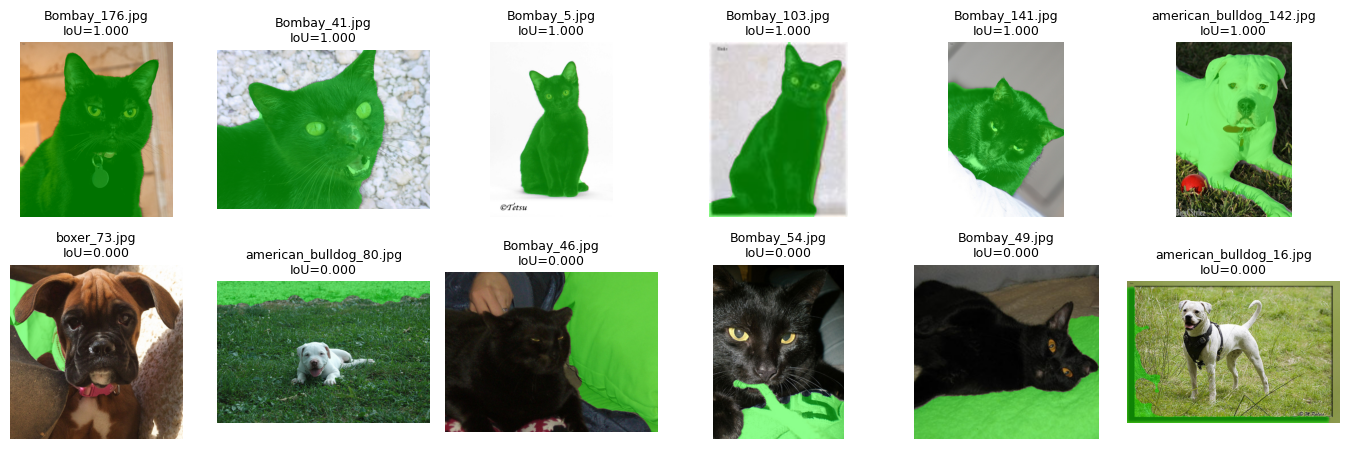

In [34]:
# TODO: ranked = masks.dropna(subset=["iou"]).sort_values("iou", ascending=False)
#       по 6 строк из начала и конца; для каждой: load_rgb, segment(rgb, **FINAL), overlay(rgb, mask)
#       подписи вида "Bengal_12.jpg IoU 0.91"
#       show_grid(panels, titles, ncols=6, path=RESULTS / "best_worst.png", size=2.3)


# Сортируем фотографии по качеству сегментации
ranked = masks.dropna(subset=["iou"]).sort_values(
    "iou", ascending=False
)

# Выбираем 6 лучших и 6 худших
selected = pd.concat([
    ranked.head(6),
    ranked.tail(6)
])

panels = []
titles = []

for r in selected.itertuples():
    # Загружаем исходное изображение
    rgb = load_rgb(r.filename)

    # Получаем итоговую маску
    mask = segment(rgb, **FINAL)

    # Накладываем маску на фотографию
    panels.append(overlay(rgb, mask))

    # Подпись с названием и IoU
    titles.append(f"{r.filename}\nIoU={r.iou:.3f}")

# Сохраняем галерею
show_grid(
    panels,
    titles,
    ncols=6,
    path=RESULTS / "best_worst.png",
    size=2.3
)


## Выгрузка

Ячейка ниже проверяет, что все 9 файлов на месте, и печатает главное для отчёта. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab02/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [35]:
print(f"вариант {VARIANT} | шум {NOISE_NAME} | BEST_FILTER = {BEST_FILTER} | CHANNEL = {CHANNEL}")

expected = {"part1_stats.csv", "histograms.png", "illumination.png", "filters.csv", "filters.png",
            "pipeline.png", "ablation.csv", "masks.csv", "best_worst.png"}
missing = sorted(expected - {p.name for p in RESULTS.iterdir()})
print("не хватает:", ", ".join(missing) if missing else "ничего, все 9 файлов на месте")

вариант 15 | шум kind=gauss sigma=30 | BEST_FILTER = gaussian7 | CHANNEL = gray
не хватает: ничего, все 9 файлов на месте


In [36]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)

архив: /content/results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>